# MedSAM demo on a public brain MRI

Trying to reproduce the main ideas of the MedSAM paper on data anyone can download, before using it on our GluCEST data.

Paper: Ma J, He Y, Li F, Han L, You C, Wang B. *Segment anything in medical images.* Nature Communications 15, 654 (2024).
Code: https://github.com/bowang-lab/MedSAM

What I took from the paper:
- MedSAM is SAM (ViT-B version) fine-tuned on **1,570,263 medical image-mask pairs** (10 imaging modalities, 30+ cancer types)
- The prompt is a **bounding box**. You box the thing, it gives you the mask
- 3 parts: image encoder (ViT, 1024x1024 image -> 256x64x64 embedding), prompt encoder (the box), mask decoder (makes the mask)
- Pre-processing for MRI: clip to the 0.5 and 99.5 percentile, scale to 0-255, 3 channels, resize to 1024x1024
- During training the boxes were randomly shifted by 0-20 pixels, so it should not need a perfect box
- They score with **DSC** (Dice) and **NSD** (normalized surface distance) and compare against vanilla SAM
- 3D scans are done slice by slice with a box on every slice

Plan for this notebook:
1. Load the data
2. EDA (look at the data before using the model)
3. Pre-processing like the paper
4. Load MedSAM and look at the 3 parts
5. Segment one structure with one box
6. MedSAM vs SAM (like the paper)
7. How much does a bad box hurt?
8. Different MRI contrasts (T1, T2, PD)
9. 3D segmentation slice by slice
10. What I learned

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import torch
import torch.nn.functional as F
from scipy import ndimage as ndi
from skimage import transform
from nilearn import datasets, image
from transformers import SamModel, SamProcessor

In [2]:
np.random.seed(42)
torch.manual_seed(42)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


## 1. Load the data

The MRI is the **ICBM152 2009** template from nilearn. It is an average of 152 healthy adult brains and has T1, T2 and PD
contrasts on the same 1 mm grid, which is nice because I can test more than one MRI contrast.

For the labels I use the **Harvard-Oxford subcortical atlas** (also from nilearn). These are going to be my "ground
truth" masks and also where I get the boxes from.

Everything downloads the first time.

In [3]:
icbm = datasets.fetch_icbm152_2009()
print(icbm.keys())

[fetch_icbm152_2009] Dataset directory found: /home/jurgen/nilearn_data/icbm152_2009
dict_keys(['description', 'csf', 'gm', 'wm', 'pd', 't1', 't2', 't2_relax', 'eye_mask', 'face_mask', 'mask'])


In [4]:
T1_img = image.reorder_img(image.load_img(icbm['t1']), resample='continuous')
T2_img = image.resample_to_img(icbm['t2'], T1_img)
PD_img = image.resample_to_img(icbm['pd'], T1_img)
mask_img = image.resample_to_img(icbm['mask'], T1_img, interpolation='nearest')

T1_vol = T1_img.get_fdata().astype(np.float32)
T2_vol = T2_img.get_fdata().astype(np.float32)
PD_vol = PD_img.get_fdata().astype(np.float32)
brainMask = mask_img.get_fdata() > 0.5

print(T1_vol.shape, T2_vol.shape, PD_vol.shape, brainMask.shape)
print('voxel size (mm):', T1_img.header.get_zooms())

(197, 233, 189) (197, 233, 189) (197, 233, 189) (197, 233, 189)
voxel size (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))


In [5]:
ho = datasets.fetch_atlas_harvard_oxford('sub-maxprob-thr25-1mm')
atlas_img = image.resample_to_img(ho.maps, T1_img, interpolation='nearest')  # nearest so the labels stay integers
atlasLabels = np.rint(atlas_img.get_fdata()).astype(int)

print(atlasLabels.shape)
print(np.unique(atlasLabels))

[fetch_atlas_harvard_oxford] Dataset directory found: /home/jurgen/nilearn_data/fsl


(197, 233, 189)


[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21]


In [6]:
labelNames = list(ho.labels)
for i, name in enumerate(labelNames):
    print(i, name)

0 Background
1 Left Cerebral White Matter
2 Left Cerebral Cortex
3 Left Lateral Ventricle
4 Left Thalamus
5 Left Caudate
6 Left Putamen
7 Left Pallidum
8 Brain-Stem
9 Left Hippocampus
10 Left Amygdala
11 Left Accumbens
12 Right Cerebral White Matter
13 Right Cerebral Cortex
14 Right Lateral Ventricle
15 Right Thalamus
16 Right Caudate
17 Right Putamen
18 Right Pallidum
19 Right Hippocampus
20 Right Amygdala
21 Right Accumbens


## 2. EDA

### What do the images look like?
First the raw images in 3 planes. The template still has the skull and scalp, so I also show the brain mask.

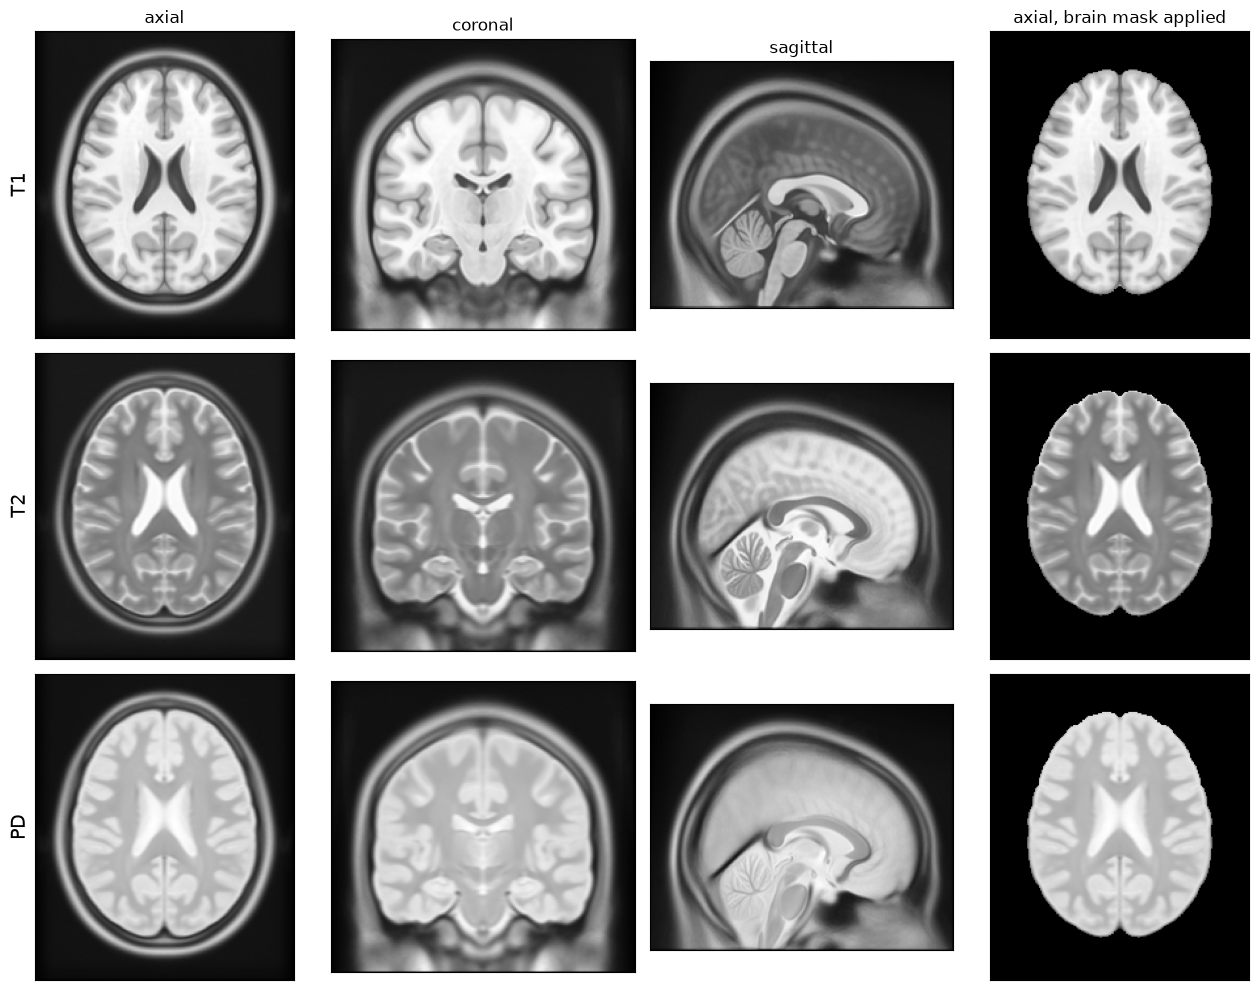

In [7]:
mid_x = T1_vol.shape[0] // 2
mid_y = T1_vol.shape[1] // 2
mid_z = T1_vol.shape[2] // 2

# rot90 so the front of the head / the top of the head is up
fig, ax = plt.subplots(3, 4, figsize=(13, 10))
for row, (name, vol) in enumerate([('T1', T1_vol), ('T2', T2_vol), ('PD', PD_vol)]):
    ax[row, 0].imshow(np.rot90(vol[:, :, mid_z]), cmap='gray')
    ax[row, 1].imshow(np.rot90(vol[:, mid_y, :]), cmap='gray')
    ax[row, 2].imshow(np.rot90(vol[mid_x, :, :]), cmap='gray')
    ax[row, 3].imshow(np.rot90((vol * brainMask)[:, :, mid_z]), cmap='gray')
    ax[row, 0].set_ylabel(name, fontsize=14)
ax[0, 0].set_title('axial')
ax[0, 1].set_title('coronal')
ax[0, 2].set_title('sagittal')
ax[0, 3].set_title('axial, brain mask applied')
for a in ax.flat:
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.show()

I only care about the brain so I apply the brain mask to all 3 contrasts.

In [8]:
T1_vol = T1_vol * brainMask
T2_vol = T2_vol * brainMask
PD_vol = PD_vol * brainMask

### Basic stats of the intensities (brain voxels only)

In [9]:
stats = []
for name, vol in [('T1', T1_vol), ('T2', T2_vol), ('PD', PD_vol)]:
    v = vol[brainMask]
    stats.append({'contrast': name, 'min': v.min(), 'max': v.max(), 'mean': v.mean(), 'std': v.std(),
                  'p0.5': np.percentile(v, 0.5), 'p99.5': np.percentile(v, 99.5)})
stats_df = pd.DataFrame(stats)
stats_df.round(2)

,contrast,min,max,mean,std,p0.5,p99.5
0,T1,10.61,96.440002,67.040001,13.61,24.309999,88.599998
1,T2,12.12,105.000000,63.599998,12.36,37.580002,100.010002
2,PD,6.99,95.970001,71.029999,7.86,33.459999,86.150002


The paper clips MRI to the 0.5 and 99.5 percentile. Plotting the histograms with those two lines to see what gets cut off.

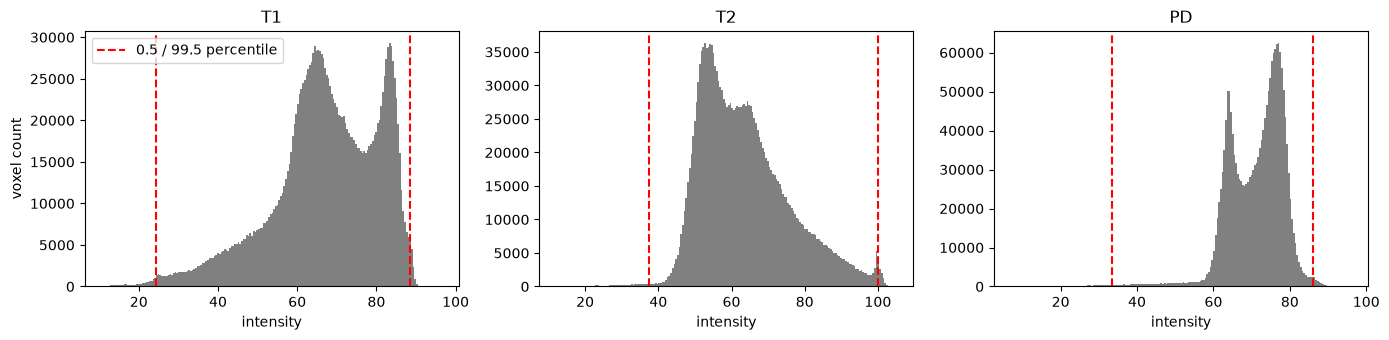

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, (name, vol) in zip(ax, [('T1', T1_vol), ('T2', T2_vol), ('PD', PD_vol)]):
    v = vol[brainMask]
    lo, hi = np.percentile(v, [0.5, 99.5])
    a.hist(v, bins=200, color='gray')
    a.axvline(lo, color='red', linestyle='--', label='0.5 / 99.5 percentile')
    a.axvline(hi, color='red', linestyle='--')
    a.set_title(name)
    a.set_xlabel('intensity')
ax[0].set_ylabel('voxel count')
ax[0].legend()
plt.tight_layout()
plt.show()

##### T1 has 2 clear peaks (grey matter and white matter) plus a small CSF bump on the left. T2 is kind of flipped (CSF bright). The percentile clipping only removes a tiny tail, so it should not change much here, it matters more for scans with bright artifacts.

### The labels
I'm skipping cortex and white matter (they are huge and not really "objects" you would box) and keeping the
subcortical structures.

In [11]:
structNames = ['Left Lateral Ventricle', 'Right Lateral Ventricle',
               'Left Caudate', 'Right Caudate',
               'Left Putamen', 'Right Putamen',
               'Left Thalamus', 'Right Thalamus',
               'Left Hippocampus', 'Right Hippocampus',
               'Brain-Stem']

def get_mask(name):
    return atlasLabels == labelNames.index(name)

label_info = []
for name in structNames:
    m = get_mask(name)
    zs = np.where(m.any(axis=(0, 1)))[0]
    label_info.append({'structure': name, 'voxels': m.sum(), 'volume_mL': m.sum() / 1000,
                       'first_axial_slice': zs.min(), 'last_axial_slice': zs.max(), 'n_axial_slices': len(zs)})
label_df = pd.DataFrame(label_info)
label_df

,structure,voxels,volume_mL,first_axial_slice,last_axial_slice,n_axial_slices
0,Left Lateral Ventricle,9299,9.299,68,100,33
1,Right Lateral Ventricle,8283,8.283,69,100,32
2,Left Caudate,3949,3.949,65,98,34
3,Right Caudate,4127,4.127,66,98,33
4,Left Putamen,6397,6.397,59,86,28
5,Right Putamen,6397,6.397,60,86,27
6,Left Thalamus,10385,10.385,67,91,25
7,Right Thalamus,10211,10.211,67,92,26
8,Left Hippocampus,5575,5.575,43,77,35
9,Right Hippocampus,5688,5.688,43,78,36


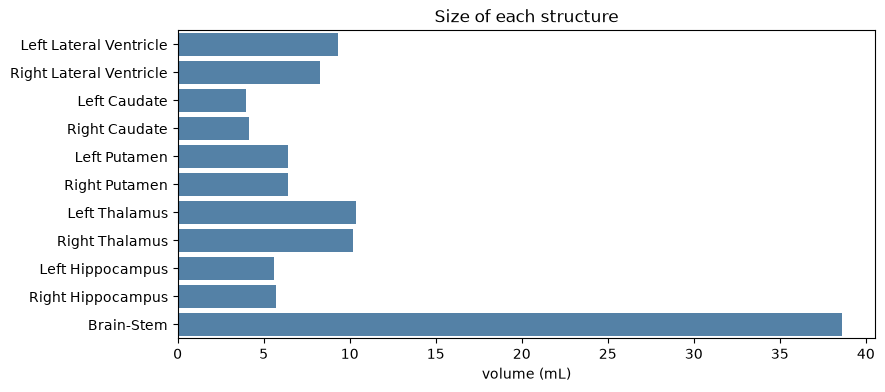

In [12]:
plt.figure(figsize=(9, 4))
sns.barplot(data=label_df, y='structure', x='volume_mL', color='steelblue')
plt.title('Size of each structure')
plt.xlabel('volume (mL)')
plt.ylabel('')
plt.show()

Checking that the atlas actually lines up with the image. The atlas comes from FSL's version of MNI space which is
close to the ICBM 2009 template but not exactly the same, so I expect it to be off by a bit in places.

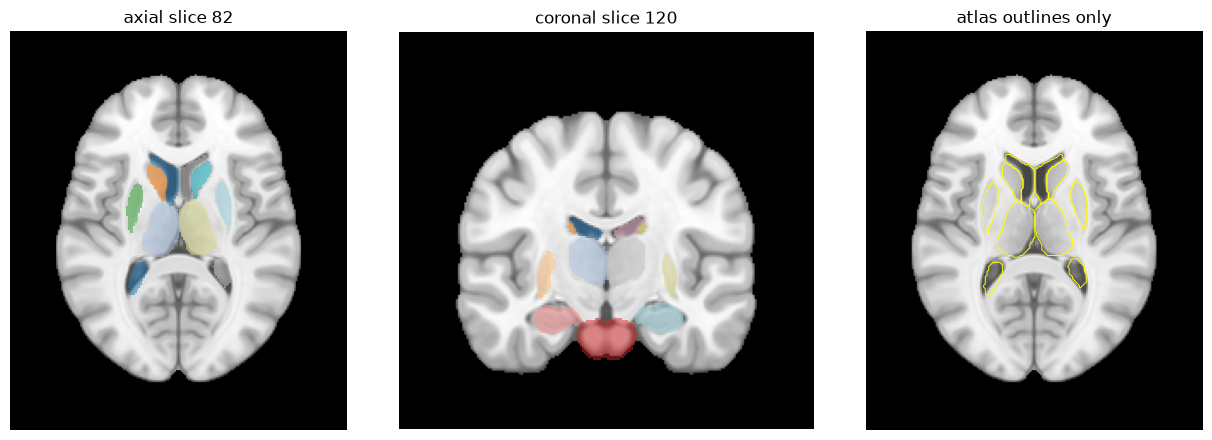

In [13]:
subcort = np.zeros_like(atlasLabels)
for name in structNames:
    subcort[get_mask(name)] = labelNames.index(name)

z_show = np.argmax(get_mask('Left Caudate').sum(axis=(0, 1)))
y_show = np.argmax(get_mask('Left Hippocampus').sum(axis=(0, 2)))

fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
ax[0].imshow(np.rot90(T1_vol[:, :, z_show]), cmap='gray')
ax[0].imshow(np.rot90(np.ma.masked_equal(subcort[:, :, z_show], 0)), cmap='tab20', alpha=0.5, interpolation='nearest')
ax[0].set_title(f'axial slice {z_show}')
ax[1].imshow(np.rot90(T1_vol[:, y_show, :]), cmap='gray')
ax[1].imshow(np.rot90(np.ma.masked_equal(subcort[:, y_show, :], 0)), cmap='tab20', alpha=0.5, interpolation='nearest')
ax[1].set_title(f'coronal slice {y_show}')
ax[2].imshow(np.rot90(T1_vol[:, :, z_show]), cmap='gray')
for name in structNames:
    m = np.rot90(get_mask(name)[:, :, z_show])
    if m.any():
        ax[2].contour(m, [0.5], colors='yellow', linewidths=0.7)
ax[2].set_title('atlas outlines only')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

### How much contrast does each structure have?
MedSAM can only find an edge if the image has one. For each structure I compare the mean intensity inside it with a
3 voxel ring around it (in 3D). Contrast = |inside - ring| / std of the brain. My guess is that low contrast structures will be harder.

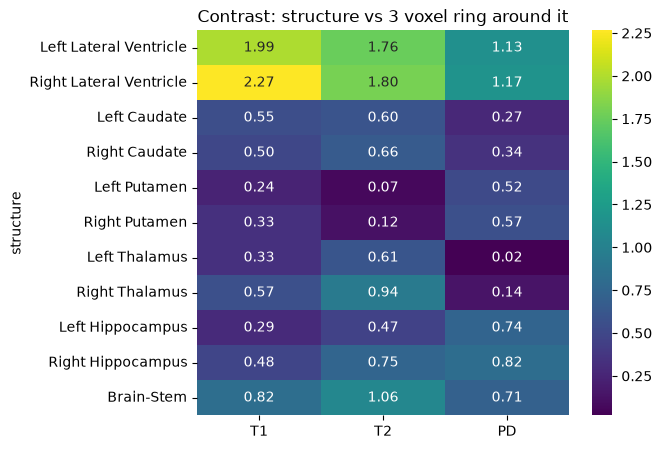

In [14]:
contrast_rows = []
for name in structNames:
    m = get_mask(name)
    ring = ndi.binary_dilation(m, iterations=3) & ~m & brainMask
    row = {'structure': name}
    for cname, vol in [('T1', T1_vol), ('T2', T2_vol), ('PD', PD_vol)]:
        row[cname] = abs(vol[m].mean() - vol[ring].mean()) / vol[brainMask].std()
    contrast_rows.append(row)
contrast_df = pd.DataFrame(contrast_rows).set_index('structure')

plt.figure(figsize=(6, 5))
sns.heatmap(contrast_df, annot=True, fmt='.2f', cmap='viridis')
plt.title('Contrast: structure vs 3 voxel ring around it')
plt.show()

##### The ventricles stand out a lot (CSF vs tissue) in every contrast. Putamen and thalamus have very little contrast against the tissue around them, so I would expect MedSAM to have trouble there.

## 3. Pre-processing like the paper

Steps from the paper / their inference code (`MedSAM_Inference.py`):
1. clip to 0.5 - 99.5 percentile
2. scale to 0 - 255
3. copy to 3 channels (the model was built for RGB)
4. resize to 1024 x 1024
5. scale to 0 - 1 for the model

In [15]:
def get_axial(vol, z):
    return np.rot90(vol[:, :, z])

def preprocess_like_paper(img2d):
    # --- A. clip
    v = img2d[img2d > 0]
    lo, hi = np.percentile(v, [0.5, 99.5])
    img = np.clip(img2d, lo, hi)
    # --- B. 0 to 255
    img = (img - lo) / (hi - lo) * 255.0
    img[img2d == 0] = 0
    # --- C. 3 channels
    img_3c = np.repeat(img[:, :, None], 3, axis=-1)
    # --- D. resize to 1024
    img_1024 = transform.resize(img_3c, (1024, 1024), order=3, preserve_range=True, anti_aliasing=True)
    # --- E. 0 to 1
    img_1024 = (img_1024 - img_1024.min()) / np.clip(img_1024.max() - img_1024.min(), 1e-8, None)
    return img_3c.astype(np.uint8), img_1024

In [16]:
slice_z = z_show
img2d = get_axial(T1_vol, slice_z)
img_3c, img_1024 = preprocess_like_paper(img2d)

print('raw slice:', img2d.shape, img2d.dtype, img2d.min(), img2d.max())
print('0-255, 3 channels:', img_3c.shape, img_3c.dtype, img_3c.min(), img_3c.max())
print('model input:', img_1024.shape, img_1024.min(), img_1024.max())

raw slice: (233, 197) float32 0.0 89.79736
0-255, 3 channels: (233, 197, 3) uint8 0 255
model input: (1024, 1024, 3) 0.0 1.0


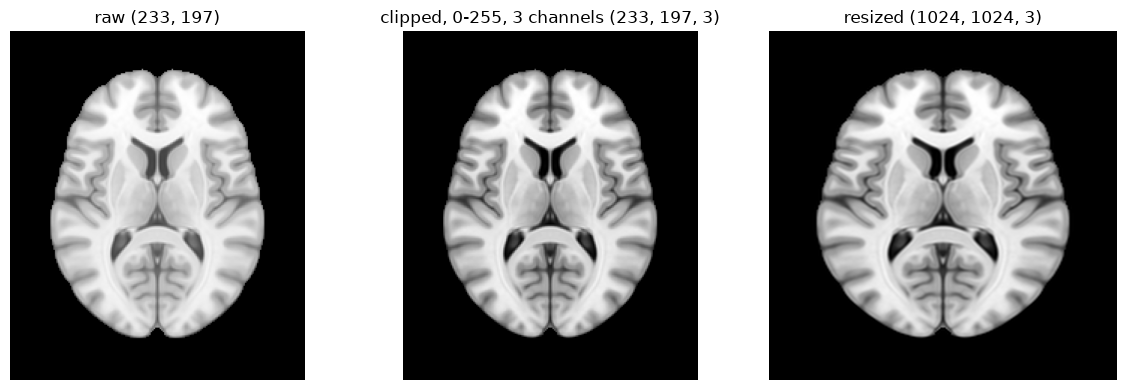

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(img2d, cmap='gray')
ax[0].set_title(f'raw {img2d.shape}')
ax[1].imshow(img_3c)
ax[1].set_title(f'clipped, 0-255, 3 channels {img_3c.shape}')
ax[2].imshow(img_1024)
ax[2].set_title(f'resized {img_1024.shape}')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

##### The slice is 233 x 197 so the resize to a square stretches it a little. The paper just resizes so I'm doing the same.

## 4. Load MedSAM

There are 2 conversions of the official MedSAM checkpoint on Hugging Face: `wanglab/medsam-vit-base` (the one most
tutorials use) and `flaviagiammarino/medsam-vit-base`. My first run used the wanglab one and MedSAM did way worse
than plain SAM, which made no sense after reading the paper. So I compared the weights of both against the original SAM.

In [18]:
t0 = time.time()
medsam_wanglab = SamModel.from_pretrained('wanglab/medsam-vit-base').to(device)
medsam_flavia = SamModel.from_pretrained('flaviagiammarino/medsam-vit-base').to(device)
sam = SamModel.from_pretrained('facebook/sam-vit-base').to(device)
print(f'loaded 3 models in {time.time() - t0:.1f} s')

loaded 3 models in 1.1 s


In [19]:
sam_weights = sam.state_dict()
weight_rows = []
for model_name, m in [('wanglab', medsam_wanglab), ('flaviagiammarino', medsam_flavia)]:
    w = m.state_dict()
    for part in ['vision_encoder', 'prompt_encoder', 'mask_decoder']:
        keys = [k for k in w if k.startswith(part)]
        n_same = sum(torch.equal(w[k], sam_weights[k]) for k in keys)
        weight_rows.append({'checkpoint': model_name, 'part': part, 'tensors': len(keys),
                            'identical to SAM': n_same})
pd.DataFrame(weight_rows)

,checkpoint,part,tensors,identical to SAM
0,wanglab,vision_encoder,177,177
1,wanglab,prompt_encoder,17,17
2,wanglab,mask_decoder,120,24
3,flaviagiammarino,vision_encoder,177,0
4,flaviagiammarino,prompt_encoder,17,17
5,flaviagiammarino,mask_decoder,120,6


##### The wanglab image encoder is exactly the original SAM encoder, every single tensor. Only its mask decoder was changed. In the paper they fine-tune the image encoder AND the mask decoder (only the prompt encoder is frozen, which matches: prompt encoder identical in both). So the wanglab upload is missing the fine-tuned encoder. The flaviagiammarino one has a changed encoder, so that is the one I use as "MedSAM" from now on. (I keep the wanglab one around for the comparison in section 6.)

In [20]:
medsam = medsam_flavia
_ = medsam.eval()
_ = medsam_wanglab.eval()
_ = sam.eval()

In [21]:
def count_params(module):
    return sum(p.numel() for p in module.parameters()) / 1e6

print(f'image encoder:  {count_params(medsam.vision_encoder):.1f} M parameters')
print(f'prompt encoder: {count_params(medsam.prompt_encoder):.3f} M parameters')
print(f'mask decoder:   {count_params(medsam.mask_decoder):.1f} M parameters')
print(f'total:          {count_params(medsam):.1f} M parameters')

image encoder:  89.7 M parameters
prompt encoder: 0.006 M parameters
mask decoder:   4.1 M parameters
total:          93.7 M parameters


##### Almost all the parameters are in the image encoder. The prompt encoder and mask decoder are tiny, that is why you only need to run the encoder once per image and then you can try lots of boxes quickly.

### Image encoder
Image goes in, a 256 x 64 x 64 embedding comes out (so every "pixel" of the embedding covers 16 x 16 pixels of the 1024 image).

In [22]:
def get_embedding(model, img_1024):
    x = torch.tensor(img_1024, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0).to(device)
    with torch.no_grad():
        emb = model.get_image_embeddings(x)
    return emb

t0 = time.time()
emb = get_embedding(medsam, img_1024)
print(f'encoder time: {time.time() - t0:.2f} s')
print(emb.shape)

encoder time: 0.94 s
torch.Size([1, 256, 64, 64])


I can't look at 256 channels, so I squash them to 3 with PCA and show them as RGB, plus a few single channels.

variance explained by 3 PCs: [0.293 0.104 0.08 ]


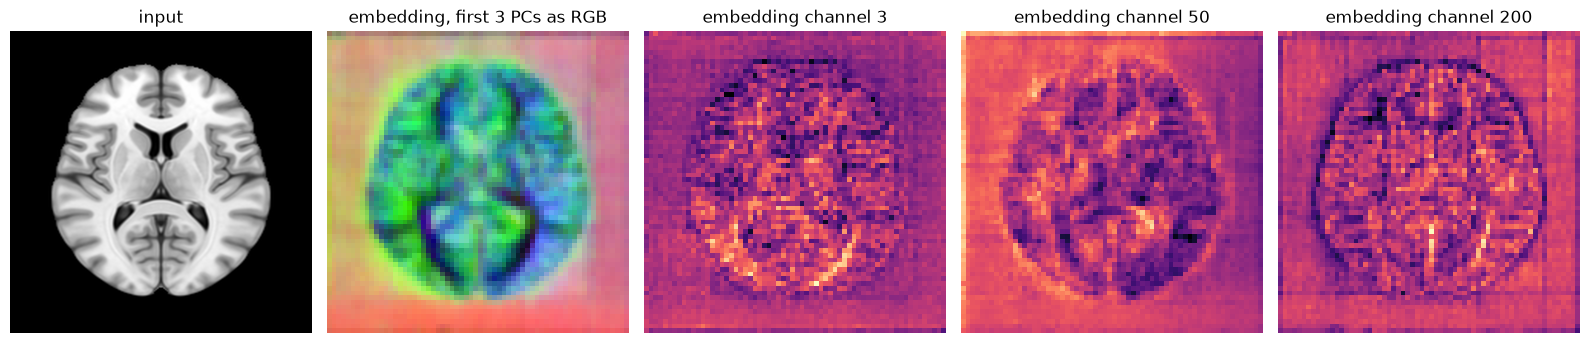

In [23]:
from sklearn.decomposition import PCA

e = emb[0].cpu().numpy()          # 256 x 64 x 64
e_flat = e.reshape(256, -1).T     # 4096 x 256
pca = PCA(n_components=3)
e_pca = pca.fit_transform(e_flat).reshape(64, 64, 3)
e_pca = (e_pca - e_pca.min(axis=(0, 1))) / (e_pca.max(axis=(0, 1)) - e_pca.min(axis=(0, 1)))
print('variance explained by 3 PCs:', pca.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(1, 5, figsize=(16, 3.5))
ax[0].imshow(img_1024)
ax[0].set_title('input')
ax[1].imshow(e_pca)
ax[1].set_title('embedding, first 3 PCs as RGB')
for a, ch in zip(ax[2:], [3, 50, 200]):
    a.imshow(e[ch], cmap='magma')
    a.set_title(f'embedding channel {ch}')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

## 5. One structure, one box

The box comes from the atlas mask (tight box + 2 pixels, kind of what a person would draw). The box has to be
converted to the 1024 x 1024 coordinates. Then the prompt encoder + mask decoder give a 256 x 256 mask (logits)
that gets sigmoid + resized back to the slice size, same as in `medsam_inference` in their repo.

In [24]:
def box_from_mask(m, pad=2):
    rows, cols = np.where(m)
    H, W = m.shape
    x0 = max(cols.min() - pad, 0)
    y0 = max(rows.min() - pad, 0)
    x1 = min(cols.max() + pad, W - 1)
    y1 = min(rows.max() + pad, H - 1)
    return np.array([x0, y0, x1, y1], dtype=float)

def largest_component(m):
    lab, n = ndi.label(m)
    if n <= 1:
        return m
    sizes = ndi.sum(m, lab, range(1, n + 1))
    return lab == (np.argmax(sizes) + 1)

def medsam_predict(model, emb, box, H, W):
    box_1024 = box / np.array([W, H, W, H]) * 1024
    box_t = torch.tensor(box_1024, dtype=torch.float32)[None, None, :].to(device)  # (batch, n_boxes, 4)
    with torch.no_grad():
        out = model(image_embeddings=emb, input_boxes=box_t, multimask_output=False)
    low_res = torch.sigmoid(out.pred_masks[0, 0])                       # 1 x 256 x 256
    prob = F.interpolate(low_res[None], size=(H, W), mode='bilinear', align_corners=False)[0, 0]
    return prob.cpu().numpy()

For scoring, the paper uses **DSC** (Dice, overlap) and **NSD** (normalized surface distance: the fraction of the
boundary that is within a tolerance of the true boundary). Their eval code uses a 2 mm tolerance, and our voxels
are 1 mm, so 2 pixels.

In [25]:
def dice(pred, gt):
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    if pred.sum() + gt.sum() == 0:
        return 1.0
    return 2 * (pred & gt).sum() / (pred.sum() + gt.sum())

def nsd(pred, gt, tol=2.0, spacing=None):
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    if pred.sum() == 0 or gt.sum() == 0:
        return 0.0
    if spacing is None:
        spacing = [1.0] * pred.ndim
    pred_border = pred ^ ndi.binary_erosion(pred)
    gt_border = gt ^ ndi.binary_erosion(gt)
    dist_to_gt = ndi.distance_transform_edt(~gt_border, sampling=spacing)
    dist_to_pred = ndi.distance_transform_edt(~pred_border, sampling=spacing)
    good = (dist_to_gt[pred_border] <= tol).sum() + (dist_to_pred[gt_border] <= tol).sum()
    return good / (pred_border.sum() + gt_border.sum())

In [26]:
name = 'Left Caudate'
gt = largest_component(get_axial(get_mask(name), slice_z))
box = box_from_mask(gt, pad=2)
H, W = gt.shape
print('box (x0, y0, x1, y1):', box)

t0 = time.time()
prob = medsam_predict(medsam, emb, box, H, W)
print(f'decoder time: {(time.time() - t0) * 1000:.0f} ms')

pred = prob > 0.5
print(f'{name}: DSC = {dice(pred, gt):.3f}, NSD = {nsd(pred, gt):.3f}')

box (x0, y0, x1, y1): [ 78.  75.  93. 101.]
decoder time: 62 ms
Left Caudate: DSC = 0.733, NSD = 0.798


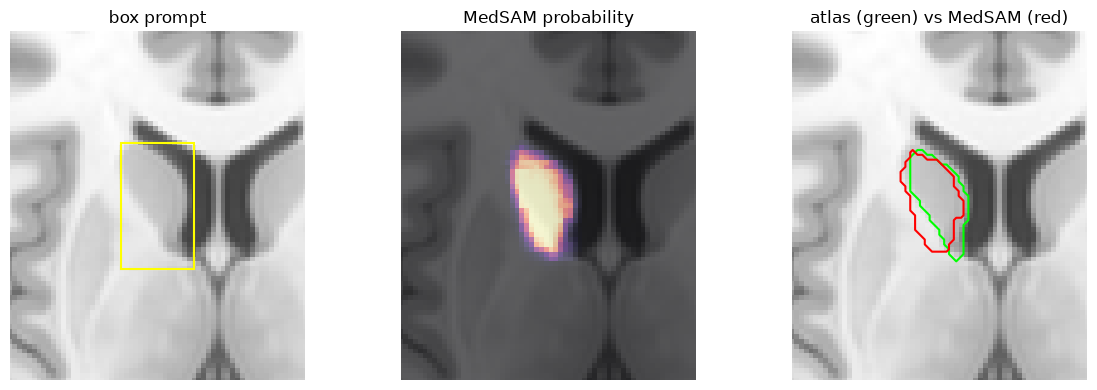

In [27]:
def draw_box(ax, box, color='yellow'):
    x0, y0, x1, y1 = box
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, linewidth=1.5))

def zoom(ax, m, pad=25):
    rows, cols = np.where(m)
    ax.set_xlim(cols.min() - pad, cols.max() + pad)
    ax.set_ylim(rows.max() + pad, rows.min() - pad)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(img2d, cmap='gray')
draw_box(ax[0], box)
ax[0].set_title('box prompt')
ax[1].imshow(img2d, cmap='gray')
ax[1].imshow(prob, cmap='magma', alpha=0.6, vmin=0, vmax=1)
ax[1].set_title('MedSAM probability')
ax[2].imshow(img2d, cmap='gray')
ax[2].contour(gt, [0.5], colors='lime')
ax[2].contour(pred, [0.5], colors='red')
ax[2].set_title('atlas (green) vs MedSAM (red)')
for a in ax:
    zoom(a, gt)
    a.axis('off')
plt.tight_layout()
plt.show()

## 6. MedSAM vs SAM

This is the main comparison in the paper: same boxes, original SAM vs MedSAM. For SAM I use its own pre-processing
(the `SamProcessor`, ImageNet normalization) on the same 0-255 image, so each model gets the input it was trained on.
I also run the wanglab upload to see how much the missing encoder matters.

Each structure is tested on the axial slice where it is biggest.

In [28]:
samProcessor = SamProcessor.from_pretrained('facebook/sam-vit-base')

def sam_predict(img_3c, box):
    inputs = samProcessor(img_3c, input_boxes=[[box.tolist()]], return_tensors='pt').to(device)
    with torch.no_grad():
        out = sam(**inputs, multimask_output=False)
    masks = samProcessor.image_processor.post_process_masks(out.pred_masks.cpu(), inputs['original_sizes'].cpu(),
                                                            inputs['reshaped_input_sizes'].cpu())
    return masks[0][0, 0].numpy()

In [29]:
def best_axial_slice(m3d):
    return int(np.argmax(m3d.sum(axis=(0, 1))))

compare_rows = []
saved = {}   # keep the masks for plotting
for name in structNames:
    z = best_axial_slice(get_mask(name))
    img2d = get_axial(T1_vol, z)
    gt = largest_component(get_axial(get_mask(name), z))
    box = box_from_mask(gt, pad=2)
    img_3c, img_1024 = preprocess_like_paper(img2d)

    emb = get_embedding(medsam, img_1024)
    pred_medsam = medsam_predict(medsam, emb, box, *gt.shape) > 0.5
    pred_sam = sam_predict(img_3c, box)
    emb_w = get_embedding(medsam_wanglab, img_1024)
    pred_wanglab = medsam_predict(medsam_wanglab, emb_w, box, *gt.shape) > 0.5

    compare_rows.append({'structure': name, 'slice': z,
                         'MedSAM DSC': dice(pred_medsam, gt), 'SAM DSC': dice(pred_sam, gt),
                         'wanglab DSC': dice(pred_wanglab, gt),
                         'MedSAM NSD': nsd(pred_medsam, gt), 'SAM NSD': nsd(pred_sam, gt),
                         'wanglab NSD': nsd(pred_wanglab, gt)})
    saved[name] = (img2d, gt, box, pred_medsam, pred_sam)

compare_df = pd.DataFrame(compare_rows)
compare_df.round(3)

,structure,slice,MedSAM DSC,SAM DSC,wanglab DSC,MedSAM NSD,SAM NSD,wanglab NSD
0,Left Lateral Ventricle,92,0.606,0.899,0.238,0.427,0.970,0.333
1,Right Lateral Ventricle,92,0.573,0.903,0.160,0.319,0.996,0.494
2,Left Caudate,82,0.733,0.877,0.780,0.798,0.980,0.880
3,Right Caudate,84,0.864,0.930,0.720,0.945,1.000,0.785
4,Left Putamen,68,0.571,0.805,0.004,0.433,0.883,0.086
5,Right Putamen,68,0.681,0.890,0.680,0.500,0.994,0.599
6,Left Thalamus,76,0.764,0.784,0.290,0.594,0.539,0.269
7,Right Thalamus,77,0.919,0.779,0.623,0.977,0.568,0.288
8,Left Hippocampus,53,0.926,0.801,0.556,0.943,0.711,0.371
9,Right Hippocampus,53,0.896,0.880,0.427,0.984,0.951,0.280


In [30]:
compare_df[['MedSAM DSC', 'SAM DSC', 'wanglab DSC', 'MedSAM NSD', 'SAM NSD', 'wanglab NSD']].describe().round(3)

,MedSAM DSC,SAM DSC,wanglab DSC,MedSAM NSD,SAM NSD,wanglab NSD
count,11.000,11.000,11.000,11.000,11.000,11.000
mean,0.756,0.858,0.423,0.662,0.856,0.413
std,0.136,0.054,0.264,0.269,0.174,0.252
min,0.571,0.779,0.004,0.319,0.539,0.086
25%,0.644,0.803,0.205,0.430,0.769,0.274
50%,0.764,0.880,0.427,0.594,0.951,0.333
75%,0.880,0.895,0.652,0.944,0.987,0.546
max,0.926,0.930,0.780,0.984,1.000,0.880


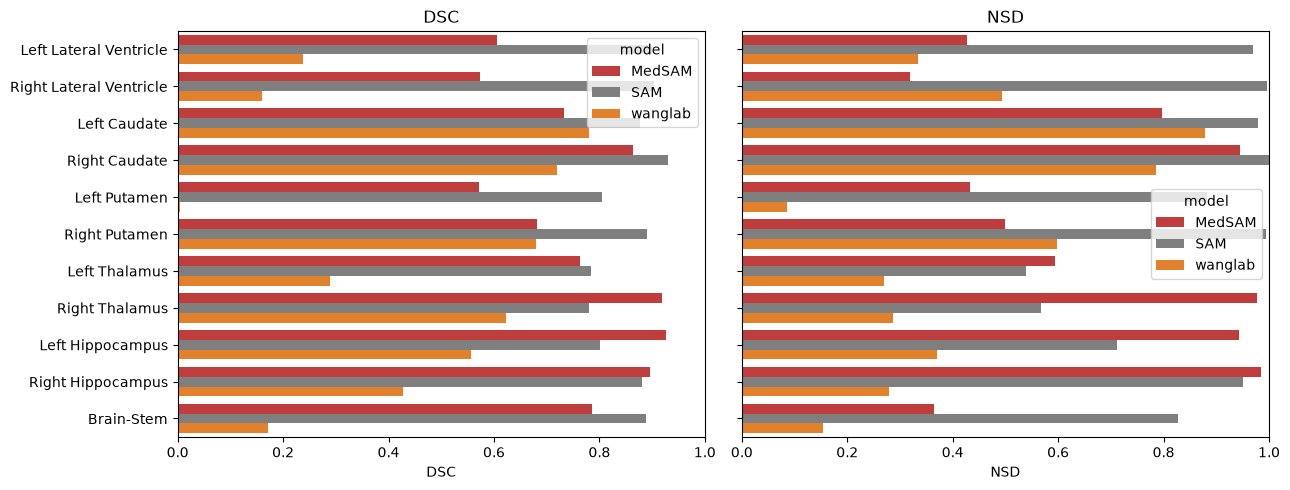

In [31]:
long_df = compare_df.melt(id_vars='structure', value_vars=['MedSAM DSC', 'SAM DSC', 'wanglab DSC',
                                                          'MedSAM NSD', 'SAM NSD', 'wanglab NSD'])
long_df['model'] = long_df['variable'].str.split(' ').str[0]
long_df['metric'] = long_df['variable'].str.split(' ').str[1]

fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for a, metric in zip(ax, ['DSC', 'NSD']):
    sns.barplot(data=long_df[long_df.metric == metric], y='structure', x='value', hue='model', ax=a,
                palette={'MedSAM': 'tab:red', 'SAM': 'tab:gray', 'wanglab': 'tab:orange'})
    a.set_title(metric)
    a.set_xlim(0, 1)
    a.set_xlabel(metric)
    a.set_ylabel('')
plt.tight_layout()
plt.show()

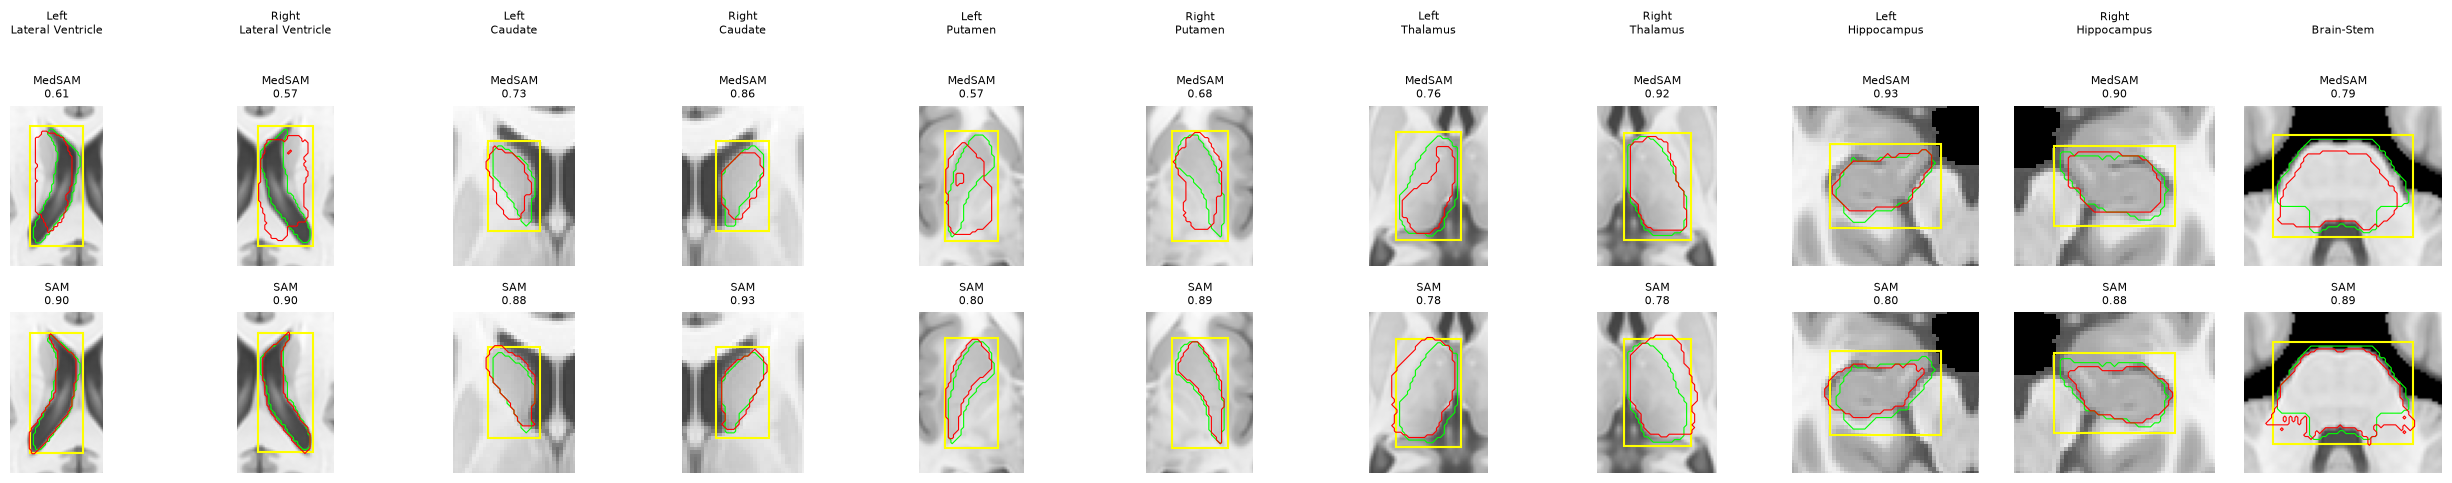

In [32]:
fig, ax = plt.subplots(2, len(structNames), figsize=(2.3 * len(structNames), 5))
for j, name in enumerate(structNames):
    img2d, gt, box, pred_medsam, pred_sam = saved[name]
    for i, (model_name, pred) in enumerate([('MedSAM', pred_medsam), ('SAM', pred_sam)]):
        a = ax[i, j]
        a.imshow(img2d, cmap='gray')
        a.contour(gt, [0.5], colors='lime', linewidths=0.8)
        if pred.any():
            a.contour(pred, [0.5], colors='red', linewidths=0.8)
        draw_box(a, box)
        zoom(a, gt, pad=12)
        a.set_title(f'{model_name}\n{dice(pred, gt):.2f}', fontsize=8)
        a.axis('off')
    ax[0, j].text(0.5, 1.45, name.replace(' ', '\n', 1), transform=ax[0, j].transAxes, ha='center', fontsize=8)
plt.tight_layout()
plt.show()

Does the contrast from the EDA explain which structures work?

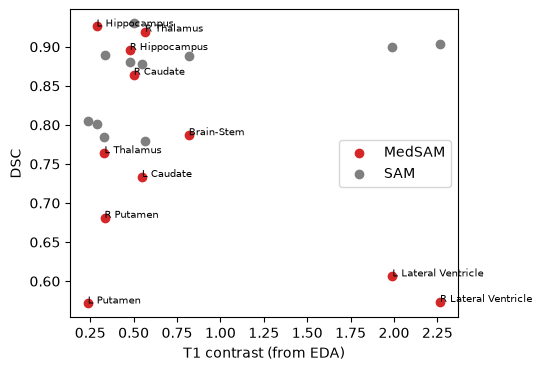

correlation contrast vs MedSAM DSC: -0.54


In [33]:
compare_df['T1 contrast'] = compare_df['structure'].map(contrast_df['T1'])

plt.figure(figsize=(5, 4))
plt.scatter(compare_df['T1 contrast'], compare_df['MedSAM DSC'], color='tab:red', label='MedSAM')
plt.scatter(compare_df['T1 contrast'], compare_df['SAM DSC'], color='tab:gray', label='SAM')
for _, r in compare_df.iterrows():
    plt.annotate(r['structure'].replace('Left ', 'L ').replace('Right ', 'R '), (r['T1 contrast'], r['MedSAM DSC']),
                 fontsize=7)
plt.xlabel('T1 contrast (from EDA)')
plt.ylabel('DSC')
plt.legend()
plt.show()

print('correlation contrast vs MedSAM DSC:', np.corrcoef(compare_df['T1 contrast'], compare_df['MedSAM DSC'])[0, 1].round(2))

## 7. How much does a bad box hurt?

In training the paper moved the box corners randomly by 0-20 pixels so the model would not need a perfect box. 20 pixels
on the 1024 image is about 4 pixels on our ~200 pixel slice. So I shift every box corner by a random amount up to
`max_shift` pixels (in or out), 10 tries per structure.

In [34]:
def shift_box(box, max_shift, H, W, rng):
    new_box = box + rng.uniform(-max_shift, max_shift, size=4)
    x0, x1 = sorted([new_box[0], new_box[2]])
    y0, y1 = sorted([new_box[1], new_box[3]])
    return np.array([max(x0, 0), max(y0, 0), min(x1, W - 1), min(y1, H - 1)])

rng = np.random.default_rng(0)
shifts = [0, 2, 4, 6, 8, 10]
n_tries = 10

robust_rows = []
for name in structNames:
    img2d, gt, box, _, _ = saved[name]
    img_3c, img_1024 = preprocess_like_paper(img2d)
    emb = get_embedding(medsam, img_1024)   # encoder once, then only the decoder
    for s in shifts:
        for t in range(n_tries if s > 0 else 1):
            b = shift_box(box, s, *gt.shape, rng)
            pred = medsam_predict(medsam, emb, b, *gt.shape) > 0.5
            robust_rows.append({'structure': name, 'max_shift_px': s, 'DSC': dice(pred, gt)})
robust_df = pd.DataFrame(robust_rows)
print(robust_df.shape)
robust_df.groupby('max_shift_px')['DSC'].agg(['mean', 'std']).round(3)

(561, 3)


,mean,std
max_shift_px,,
0,0.756,0.136
2,0.746,0.131
4,0.690,0.175
6,0.584,0.232
8,0.553,0.205
10,0.479,0.227


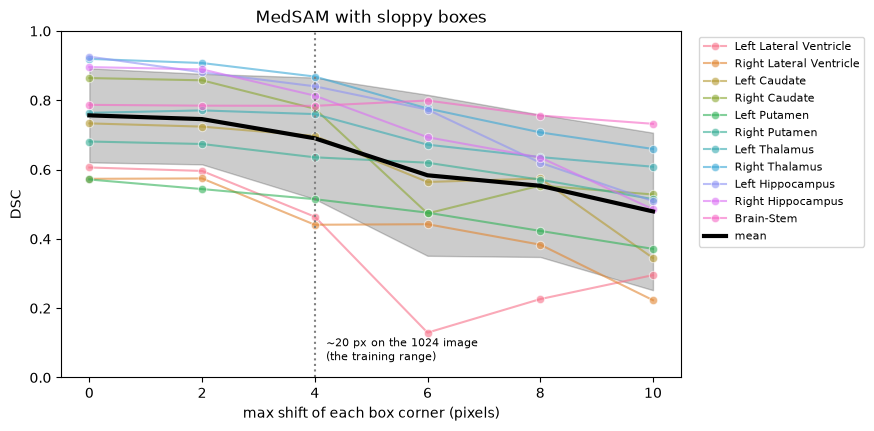

In [35]:
plt.figure(figsize=(8, 4.5))
sns.lineplot(data=robust_df, x='max_shift_px', y='DSC', hue='structure', errorbar=None, marker='o', alpha=0.6)
sns.lineplot(data=robust_df, x='max_shift_px', y='DSC', color='black', linewidth=3, label='mean', errorbar='sd')
plt.axvline(4, color='gray', linestyle=':')
plt.text(4.2, 0.05, '~20 px on the 1024 image\n(the training range)', fontsize=8)
plt.ylim(0, 1)
plt.xlabel('max shift of each box corner (pixels)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.title('MedSAM with sloppy boxes')
plt.show()

## 8. Different MRI contrasts

The paper covers lots of modalities (CT, MRI, X-ray, ultrasound, ...). I only have MRI here but I can at least try
T1, T2 and PD on the same slices with the same boxes.

In [36]:
contrast_rows2 = []
for name in structNames:
    z = best_axial_slice(get_mask(name))
    gt = largest_component(get_axial(get_mask(name), z))
    box = box_from_mask(gt, pad=2)
    for cname, vol in [('T1', T1_vol), ('T2', T2_vol), ('PD', PD_vol)]:
        _, img_1024 = preprocess_like_paper(get_axial(vol, z))
        emb = get_embedding(medsam, img_1024)
        pred = medsam_predict(medsam, emb, box, *gt.shape) > 0.5
        contrast_rows2.append({'structure': name, 'contrast': cname, 'DSC': dice(pred, gt), 'NSD': nsd(pred, gt)})
modality_df = pd.DataFrame(contrast_rows2)
modality_df.pivot(index='structure', columns='contrast', values='DSC').round(3)

contrast,PD,T1,T2
structure,,,
Brain-Stem,0.874,0.787,0.868
Left Caudate,0.819,0.733,0.891
Left Hippocampus,0.819,0.926,0.861
Left Lateral Ventricle,0.871,0.606,0.803
Left Putamen,0.839,0.571,0.798
Left Thalamus,0.835,0.764,0.762
Right Caudate,0.634,0.864,0.833
Right Hippocampus,0.906,0.896,0.820
Right Lateral Ventricle,0.841,0.573,0.901


In [37]:
modality_df.groupby('contrast')[['DSC', 'NSD']].mean().round(3)

,DSC,NSD
contrast,,
PD,0.823,0.759
T1,0.756,0.662
T2,0.826,0.756


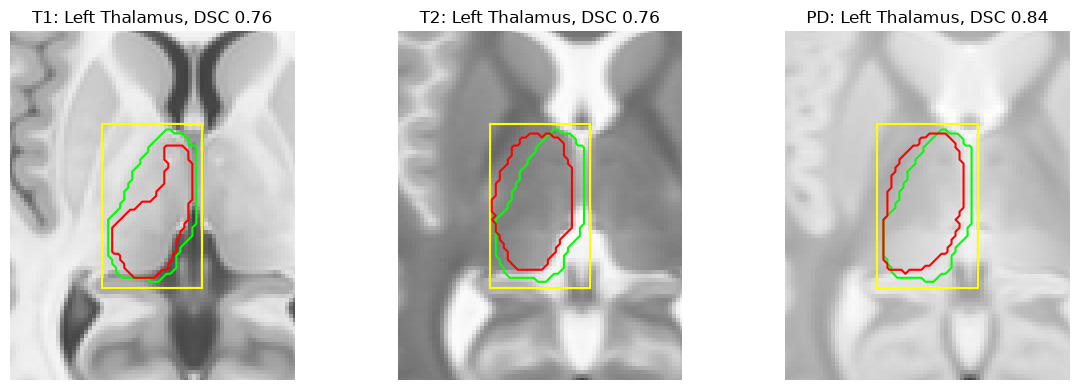

In [38]:
name = 'Left Thalamus'
z = best_axial_slice(get_mask(name))
gt = largest_component(get_axial(get_mask(name), z))
box = box_from_mask(gt, pad=2)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (cname, vol) in zip(ax, [('T1', T1_vol), ('T2', T2_vol), ('PD', PD_vol)]):
    img2d = get_axial(vol, z)
    _, img_1024 = preprocess_like_paper(img2d)
    pred = medsam_predict(medsam, get_embedding(medsam, img_1024), box, *gt.shape) > 0.5
    a.imshow(img2d, cmap='gray')
    a.contour(gt, [0.5], colors='lime')
    if pred.any():
        a.contour(pred, [0.5], colors='red')
    draw_box(a, box)
    zoom(a, gt)
    a.set_title(f'{cname}: {name}, DSC {dice(pred, gt):.2f}')
    a.axis('off')
plt.tight_layout()
plt.show()

## 9. 3D segmentation, slice by slice

MedSAM is a 2D model. In the paper, 3D scans are segmented one slice at a time with a box on each slice, then the
slices are stacked back into a volume. Doing that here for one structure on all the axial slices it shows up in.

In [39]:
def segment_3d(vol, m3d):
    pred3d = np.zeros_like(m3d, dtype=bool)
    per_slice = []
    for z in np.where(m3d.any(axis=(0, 1)))[0]:
        gt2d = get_axial(m3d, z)
        if gt2d.sum() < 5:          # skip tiny bits at the ends
            continue
        img2d = get_axial(vol, z)
        _, img_1024 = preprocess_like_paper(img2d)
        emb = get_embedding(medsam, img_1024)
        pred2d = medsam_predict(medsam, emb, box_from_mask(gt2d, 2), *gt2d.shape) > 0.5
        pred3d[:, :, z] = np.rot90(pred2d, k=-1)     # undo the rot90 to go back to volume space
        per_slice.append({'slice': z, 'gt_pixels': gt2d.sum(), 'DSC': dice(pred2d, gt2d)})
    return pred3d, pd.DataFrame(per_slice)

In [40]:
results_3d = []
slice_tables = {}
for name in ['Left Lateral Ventricle', 'Left Caudate', 'Left Thalamus']:
    m3d = get_mask(name)
    t0 = time.time()
    pred3d, per_slice_df = segment_3d(T1_vol, m3d)
    slice_tables[name] = per_slice_df
    results_3d.append({'structure': name, 'n_slices': len(per_slice_df), 'seconds': time.time() - t0,
                       '3D DSC': dice(pred3d, m3d), '3D NSD': nsd(pred3d, m3d, spacing=(1, 1, 1))})
    if name == 'Left Caudate':
        caudate_pred3d = pred3d
results_3d_df = pd.DataFrame(results_3d)
results_3d_df.round(3)

,structure,n_slices,seconds,3D DSC,3D NSD
0,Left Lateral Ventricle,31,68.589,0.216,0.347
1,Left Caudate,33,73.671,0.761,0.912
2,Left Thalamus,25,55.367,0.774,0.754


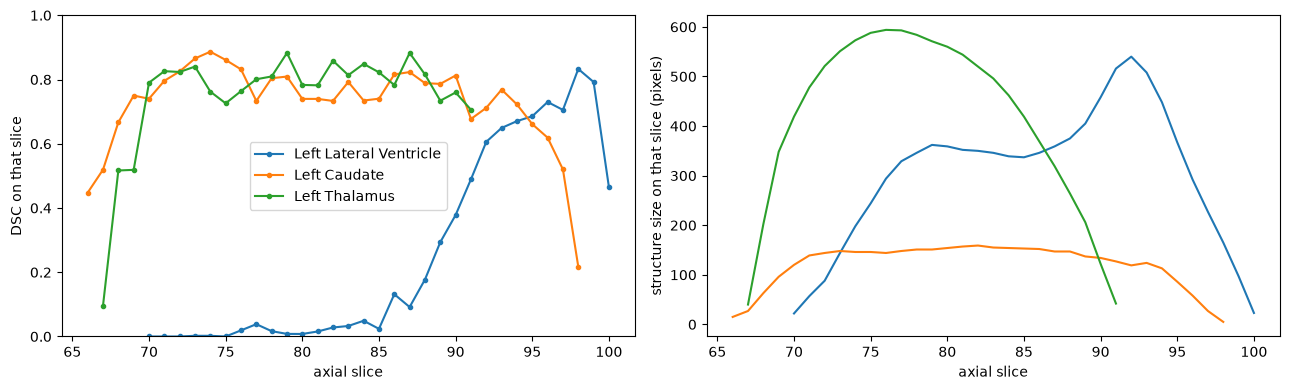

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, df in slice_tables.items():
    ax[0].plot(df['slice'], df['DSC'], marker='o', markersize=3, label=name)
    ax[1].plot(df['slice'], df['gt_pixels'], label=name)
ax[0].set_xlabel('axial slice')
ax[0].set_ylabel('DSC on that slice')
ax[0].set_ylim(0, 1)
ax[0].legend()
ax[1].set_xlabel('axial slice')
ax[1].set_ylabel('structure size on that slice (pixels)')
plt.tight_layout()
plt.show()

The caudate and thalamus are fine on almost every slice, but the ventricle is close to 0 below slice ~88 and only
works at the top. Checking what the ventricle looks like on those slices:

In [42]:
m3d = get_mask('Left Lateral Ventricle')
for z in range(70, 101, 3):
    gt2d = get_axial(m3d, z)
    pieces, n_pieces = ndi.label(gt2d)
    sizes = sorted(ndi.sum(gt2d, pieces, range(1, n_pieces + 1)), reverse=True)
    box = box_from_mask(gt2d, 2)
    box_area = (box[2] - box[0]) * (box[3] - box[1])
    print(f'slice {z}: {n_pieces} pieces, sizes {[int(x) for x in sizes]}, fills {gt2d.sum() / box_area:.0%} of the box')

slice 70: 4 pieces, sizes [11, 9, 1, 1], fills 1% of the box
slice 73: 4 pieces, sizes [61, 54, 28, 1], fills 5% of the box
slice 76: 2 pieces, sizes [176, 118], fills 9% of the box
slice 79: 2 pieces, sizes [215, 147], fills 11% of the box
slice 82: 2 pieces, sizes [219, 131], fills 12% of the box
slice 85: 2 pieces, sizes [221, 116], fills 14% of the box
slice 88: 2 pieces, sizes [216, 159], fills 19% of the box
slice 91: 1 pieces, sizes [516], fills 30% of the box
slice 94: 1 pieces, sizes [448], fills 38% of the box
slice 97: 1 pieces, sizes [227], fills 42% of the box
slice 100: 1 pieces, sizes [23], fills 26% of the box


##### Lower down, the ventricle splits into 2 or more pieces (front horn and the back part), so one box around everything is mostly brain tissue and MedSAM picks something else. A person would draw one box per piece, so trying that.

In [43]:
def segment_3d_per_piece(vol, m3d, min_pixels=5):
    pred3d = np.zeros_like(m3d, dtype=bool)
    for z in np.where(m3d.any(axis=(0, 1)))[0]:
        gt2d = get_axial(m3d, z)
        img2d = get_axial(vol, z)
        _, img_1024 = preprocess_like_paper(img2d)
        emb = get_embedding(medsam, img_1024)
        pieces, n_pieces = ndi.label(gt2d)
        pred2d = np.zeros_like(gt2d, dtype=bool)
        for k in range(1, n_pieces + 1):
            piece = pieces == k
            if piece.sum() < min_pixels:
                continue
            pred2d = pred2d | (medsam_predict(medsam, emb, box_from_mask(piece, 2), *gt2d.shape) > 0.5)
        pred3d[:, :, z] = np.rot90(pred2d, k=-1)
    return pred3d

per_piece_rows = []
for name in ['Left Lateral Ventricle', 'Left Caudate', 'Left Thalamus']:
    m3d = get_mask(name)
    pred3d = segment_3d_per_piece(T1_vol, m3d)
    per_piece_rows.append({'structure': name, '3D DSC one box per piece': dice(pred3d, m3d),
                           '3D NSD one box per piece': nsd(pred3d, m3d, spacing=(1, 1, 1))})
results_3d_df.merge(pd.DataFrame(per_piece_rows), on='structure').drop(columns=['seconds']).round(3)

,structure,n_slices,3D DSC,3D NSD,3D DSC one box per piece,3D NSD one box per piece
0,Left Lateral Ventricle,31,0.216,0.347,0.567,0.737
1,Left Caudate,33,0.761,0.912,0.761,0.912
2,Left Thalamus,25,0.774,0.754,0.790,0.789


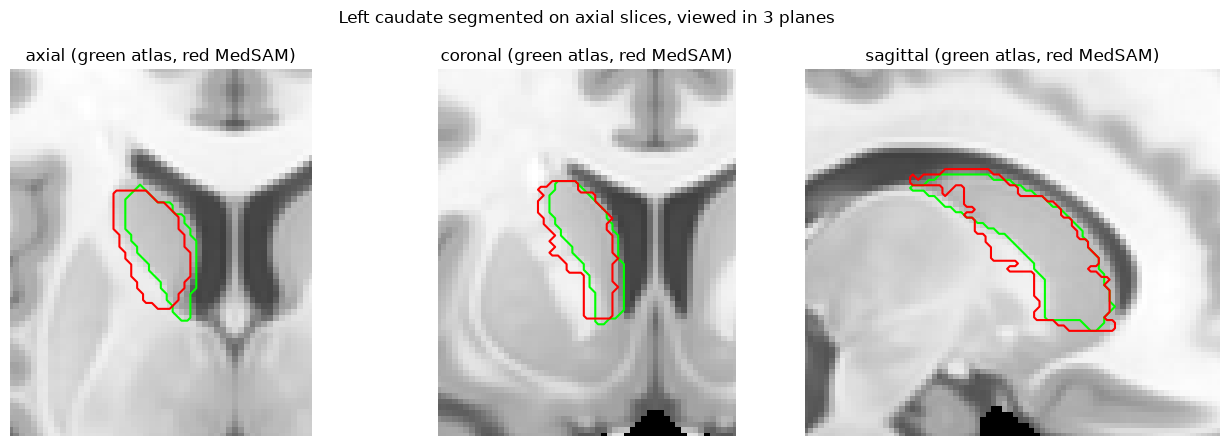

In [44]:
m3d = get_mask('Left Caudate')
cx, cy, cz = [int(c) for c in ndi.center_of_mass(m3d)]

fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
views = [('axial', np.rot90(T1_vol[:, :, cz]), np.rot90(m3d[:, :, cz]), np.rot90(caudate_pred3d[:, :, cz])),
         ('coronal', np.rot90(T1_vol[:, cy, :]), np.rot90(m3d[:, cy, :]), np.rot90(caudate_pred3d[:, cy, :])),
         ('sagittal', np.rot90(T1_vol[cx, :, :]), np.rot90(m3d[cx, :, :]), np.rot90(caudate_pred3d[cx, :, :]))]
for a, (title, im, g, p) in zip(ax, views):
    a.imshow(im, cmap='gray')
    a.contour(g, [0.5], colors='lime')
    a.contour(p, [0.5], colors='red')
    zoom(a, g, pad=20)
    a.set_title(f'{title} (green atlas, red MedSAM)')
    a.axis('off')
plt.suptitle('Left caudate segmented on axial slices, viewed in 3 planes')
plt.tight_layout()
plt.show()

## 10. What I learned

**1. Check the weights.** The popular `wanglab/medsam-vit-base` upload has the original SAM image encoder (177/177
tensors identical), only the decoder is fine-tuned. With it MedSAM got mean DSC 0.42, with the full conversion
(`flaviagiammarino`) 0.76 on the same boxes. Without checking I would have concluded MedSAM is useless.

**2. MedSAM vs SAM: on this data SAM wins**, mean DSC 0.86 vs 0.76 (NSD 0.86 vs 0.66). That is the opposite of the paper.
MedSAM was better on the hippocampus (0.93 / 0.90 vs 0.80 / 0.88) and the right thalamus (0.92 vs 0.78), but much worse
on the ventricles (~0.6 vs 0.9). My guess on why: the paper tests on real clinical scans with tumors and organs, and
this template is an average of 152 brains, so it is very smooth with clean edges. That looks more like a "natural
image", which is what SAM was trained on.

**3. Contrast did not predict which structures work** (correlation with MedSAM DSC was -0.54, so if anything the
opposite). The ventricles have the most contrast but are thin and curved, so most of the box is not ventricle. Shape
and how much of the box the object fills seem to matter more than contrast.

**4. Box shifts.** Mean DSC 0.76 with the atlas box, 0.75 with up to 2 px shift, 0.69 at 4 px (about the 20 px used in
training), 0.48 at 10 px. So it handles small mistakes but a sloppy box hurts.

**5. T1 was actually the worst contrast**: mean DSC T1 0.76, T2 0.83, PD 0.82, with the same boxes.

**6. 3D slice by slice works when there is one box per piece.** Caudate 3D DSC 0.76 and thalamus 0.79 (about 2 s per
slice on the GPU). The ventricle got 0.22 with one box per slice and 0.57 with one box per connected piece.

**Caveats:** the "ground truth" is an atlas from a slightly different MNI template, and it is one (average) brain, not
patients. The numbers are agreement with the atlas, not real accuracy.

**Next:** notebooks 02 and 03 use the wanglab weights through `medsam_glucest/model.py`, so I need to rerun them with
the full MedSAM encoder.